# Face and Object Detection with Haar Cascades

Before deep learning, Haar cascades were how every camera detected faces: a cascade of simple rectangle-feature classifiers, trained on thousands of examples, scanned over the image at many scales. OpenCV ships pre-trained cascades for faces, eyes, smiles and more. They are fast, need no GPU and no training - and this notebook uses them honestly, including their limits.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Loading a cascade and detecting faces

`cv2.CascadeClassifier` loads an XML cascade; `cv2.data.haarcascades` is the folder of shipped cascades. `detectMultiScale(gray, scaleFactor, minNeighbors)` scans a pyramid: scaleFactor shrinks the search window gradually, minNeighbors controls how many overlapping hits a detection needs - higher means fewer false positives and possibly missed faces.

Cascade loaded: True
Faces detected in the synthetic drawing: 0


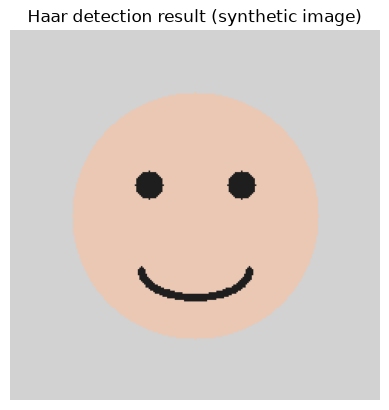

In [2]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
print("Cascade loaded:", not face_cascade.empty())
img = cv2.imread("../assets/face_test.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
print("Faces detected in the synthetic drawing:", len(faces))
for (x, y, w, h) in faces:
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
show(img, "Haar detection result (synthetic image)")

## Reading the result honestly

Our test image is a simple drawing, not a photograph - a Haar cascade trained on real faces may find zero faces in it, and that is a correct, honest result. Cascades expect photographic texture and roughly frontal, upright faces. On real photos of people the same code detects faces reliably. Never draw boxes by hand to fake a detection.

In [3]:
print("Detection array (x, y, w, h per face):")
print(faces)
print("Zero detections on a drawing is expected - the code is identical for real photos.")

Detection array (x, y, w, h per face):
()
Zero detections on a drawing is expected - the code is identical for real photos.


## Eye and smile detection inside a face region

The standard refinement: once a face box is found, search for eyes and smile only inside that box - faster and far fewer false positives. Here the region logic is demonstrated on the whole image because the synthetic face was not detected; on a real photo you would pass the face ROI instead.

In [4]:
eye_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_eye.xml")
smile_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_smile.xml")
print("Eye cascade loaded:", not eye_cascade.empty(), "| Smile cascade loaded:", not smile_cascade.empty())
eyes = eye_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=8)
smiles = smile_cascade.detectMultiScale(gray, scaleFactor=1.15, minNeighbors=12)
print("Eyes found:", len(eyes), "| Smiles found:", len(smiles))

Eye cascade loaded: True | Smile cascade loaded: True
Eyes found: 0 | Smiles found: 1


## Tuning scaleFactor and minNeighbors

These two parameters trade speed and sensitivity against false alarms. A small grid search over your own validation photos is how practitioners tune them - here we run the grid on the synthetic image just to show the mechanics and timing.

In [5]:
import time
for sf in (1.05, 1.1, 1.3):
    for mn in (3, 5, 8):
        t0 = time.time()
        f = face_cascade.detectMultiScale(gray, scaleFactor=sf, minNeighbors=mn, minSize=(30, 30))
        print(f"scaleFactor={sf}  minNeighbors={mn}  -> {len(f)} faces in {(time.time() - t0) * 1000:.0f} ms")

scaleFactor=1.05  minNeighbors=3  -> 0 faces in 14 ms
scaleFactor=1.05  minNeighbors=5  -> 0 faces in 22 ms
scaleFactor=1.05  minNeighbors=8  -> 0 faces in 14 ms
scaleFactor=1.1  minNeighbors=3  -> 0 faces in 8 ms
scaleFactor=1.1  minNeighbors=5  -> 0 faces in 8 ms
scaleFactor=1.1  minNeighbors=8  -> 0 faces in 8 ms
scaleFactor=1.3  minNeighbors=3  -> 0 faces in 54 ms
scaleFactor=1.3  minNeighbors=5  -> 0 faces in 2 ms
scaleFactor=1.3  minNeighbors=8  -> 0 faces in 3 ms


## Detecting on video frames

Per-frame detection on stored video frames uses the same function inside the read loop. Tracking (notebook 16) is usually added in practice, because raw per-frame boxes flicker. The loop below counts detections per frame on our synthetic video (a moving circle - expect zeros, which again is the honest result).

In [6]:
cap = cv2.VideoCapture("/tmp/synthetic.mp4")
counts = []
while True:
    ok, frame = cap.read()
    if not ok:
        break
    g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    counts.append(len(face_cascade.detectMultiScale(g, 1.1, 5, minSize=(30, 30))))
cap.release()
print("Frames processed:", len(counts), "| total face detections:", sum(counts))

Frames processed: 30 | total face detections: 0


## Haar cascades vs deep-learning detectors

Haar cascades: extremely fast on CPU, zero setup, but frontal faces only, sensitive to angle, occlusion and lighting, and noticeably more false positives than modern detectors. DNN-based detectors (for example the ones in OpenCV's dnn module) and modern models are more accurate and robust but heavier. Rule of thumb: Haar for quick prototypes and constrained frontal-face tasks; learned detectors for production accuracy.

In [7]:
print("Summary")
print("- Haar: pre-trained XML, detectMultiScale, CPU-fast, frontal faces")
print("- Needs: grayscale input, tuned scaleFactor / minNeighbors / minSize")
print("- Limits: pose, occlusion, lighting; drawings and cartoons usually give 0 detections")

Summary
- Haar: pre-trained XML, detectMultiScale, CPU-fast, frontal faces
- Needs: grayscale input, tuned scaleFactor / minNeighbors / minSize
- Limits: pose, occlusion, lighting; drawings and cartoons usually give 0 detections


## Key Points

- Haar cascades are pre-trained XML classifiers shipped in cv2.data.haarcascades.
- detectMultiScale scans an image pyramid; it works on grayscale images.
- scaleFactor = pyramid step, minNeighbors = strictness, minSize = smallest object.
- Search for eyes/smile inside the face ROI, not the whole image.
- Zero detections on drawings/cartoons is normal and honest - cascades expect real photos.
- Use Haar for fast prototypes; use learned detectors when accuracy matters.

## Mini Task

1. Run the face cascade on `test_image.png` and report the result honestly (it contains no people).
2. Grid-search minNeighbors in (2, 4, 6, 10) on `face_test.png` and tabulate detections and time.
3. Write one paragraph: for a school attendance camera, would you choose Haar or a DNN detector, and why?